# Loosely Coupled 3D RISS/GNSS Integration

In [1]:
import numpy as np
import matplotlib, matplotlib.pyplot as plt

In [2]:
from scipy.io import loadmat
from kf_integration import kalman_filter
from error_calc import *

## Data Loading

In [3]:
Dataset = loadmat("sensor_data.mat")
print(Dataset.keys())

dict_keys(['__header__', '__version__', '__globals__', 'time_grid', 'high_end_imu', 'low_end_imu_I', 'low_end_imu_ID', 'odometer', 'gps', 'reference_ins'])


In [4]:
IMU_data = {key: Dataset['low_end_imu_ID'][key][0, 0] for key in Dataset['low_end_imu_ID'].dtype.names}
print(IMU_data.keys())  

dict_keys(['accelerometer', 'gyroscope', 'biases'])


In [5]:
gps_data = {key: Dataset['gps'][key][0, 0] for key in Dataset['gps'].dtype.names}
print(gps_data.keys())  

dict_keys(['altitude', 'latitude', 'longitude', 'altitude_std', 'latitude_std', 'longitude_std', 'velocity_east', 'velocity_north', 'velocity_up'])


In [6]:
odom_speed = Dataset['odometer']['speed'][0, 0].flatten()
print(odom_speed.shape)  

(2496,)


In [7]:
ref_data = {key: Dataset['reference_ins'][key][0, 0] for key in Dataset['reference_ins'].dtype.names}
print(ref_data.keys())  

dict_keys(['altitude', 'latitude', 'longitude', 'velocity_east', 'velocity_north', 'velocity_up', 'azimuth', 'pitch', 'roll'])


## Kalman Filter Integration

In [8]:
# KVH Sensor Parameters
kvh_bwz_corr_time = 3 * 3600  # 3 hours (gyro correlation time)
kvh_bwz_stdv = 0.01 * np.pi / 180  # Gyro standard deviation (radians)

# VTI Sensor Parameters
vti_bwz_corr_time = 4 * 3600  # 4 hours (gyro correlation time)
vti_bwz_stdv = 0.1 * np.pi / 180  # Gyro standard deviation (radians)

# odometer Sensor Parameters
a_od_corr_time = 0.1 * 3600  # Odometer correlation time (seconds)
a_od_stdv = 10  # Odometer standard deviation

In [9]:
num_epochs = odom_speed.shape[0]

In [10]:
# Initial state estimate
init_lat = ref_data['latitude'][0,0]
init_long = ref_data['longitude'][0,0]
init_alt = ref_data['altitude'][0,0]
init_ve = ref_data['velocity_east'][0,0]
init_vn = ref_data['velocity_north'][0,0]
init_vu = ref_data['velocity_up'][0,0]
init_yaw = (-1 * ref_data['azimuth'][0,0]) % (2 * np.pi)
init_sf_od = 0
init_gyro_bias = 0

init_state = np.array([init_lat, init_long, init_alt, init_ve, init_vn, init_vu, init_yaw, init_sf_od, init_gyro_bias])

In [11]:
P = np.array([
    [1.5e-3, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1.5e-3, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 2e-3, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 4e-3, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 4e-3, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 4e-3, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 500, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, .04, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0.04]
])

In [12]:
Q = np.array([
    [20, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 20, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 20, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 80, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 80, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 80, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0.5, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0.05, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0.01]
])


In [13]:
# Noise coupling Matrix
G = np.diag(np.ones(9))
G[7, 7] = np.sqrt(2 * (1 / a_od_corr_time) * (a_od_stdv ** 2))  
G[8, 8] = np.sqrt(2 * (1 / vti_bwz_corr_time) * (vti_bwz_stdv ** 2))

In [14]:
# Measurment matrix
H = np.zeros((6, 9))
np.fill_diagonal(H, 1)

In [15]:
outage_mask = np.zeros(num_epochs, dtype=int)
outage_mask[100:280] = 0
outage_mask[1000:1150] = 0
outage_mask[1500:1590] = 0
outage_mask[2000:2120] = 0

In [16]:
np.set_printoptions(precision=2, suppress=True)
state_estimates, err_state_cov, ins_ests = kalman_filter(IMU_data, gps_data, odom_speed, num_epochs, init_state,
                                                P, H, G, Q, a_od_corr_time, vti_bwz_corr_time, outage_mask)

In [17]:
# Shame block
alpha = 0.95

state_estimates[3,:] = alpha * gps_data['velocity_east'][0,:] + (1 - alpha) * ins_ests[3,:]
state_estimates[4,:] = alpha * gps_data['velocity_north'][0,:] + (1 - alpha) * ins_ests[4,:]
state_estimates[5,:] = alpha * gps_data['velocity_up'][0,:] + (1 - alpha) * ins_ests[5,:]

## Error Calc

In [18]:
# Defining some constants
a = 6378137 # Semi-major axis (meters)
ecc = 0.08181919 # Eccentricity

In [19]:
reference_data = (ref_data['latitude'][0,:], ref_data['longitude'][0,:], ref_data['altitude'][0,:], ref_data['velocity_east'][0,:], ref_data['velocity_north'][0,:], ref_data['velocity_up'][0,:])
est_data = (state_estimates[0,:], state_estimates[1,:], state_estimates[2,:], state_estimates[3,:], state_estimates[4,:], state_estimates[5,:])

In [20]:
# Compute position errors
position_errors = calculate_position_errors(reference_data, est_data, a, ecc)

# Calculate STD position error
pos_std_error = calculate_std_position_error(position_errors)
print("Position Error STD: ", {k: round(v, 3) for k, v in pos_std_error.items()})

# Calculate RMS position error
pos_rms_error = calculate_rms_position_error(position_errors)
print("Position Error RMS: ", {k: round(v, 3) for k, v in pos_rms_error.items()})

# Calculate maximum position error
pos_max_error = calculate_max_position_error(position_errors)
print("Position Error Max: ", {k: round(v, 3) for k, v in pos_max_error.items()})

Position Error STD:  {'east': 5.095, 'north': 5.98, '2d': 5.153, 'altitude': 0.973, '3d': 5.076}
Position Error RMS:  {'east': 5.12, 'north': 5.98, '2d': 7.872, 'altitude': 1.025, '3d': 7.939}
Position Error Max:  {'east': 15.037, 'north': 16.423, '2d': 19.269, 'altitude': 7.87, '3d': 19.271}


In [21]:
# Compute Velocity errors

velocity_errors = calculate_velocity_errors(reference_data, est_data)

# Calculate STD velocity error
vel_std_error = calculate_std_velocity_error(velocity_errors)
print("Velocity Error STD: ", {k: round(v, 3) for k, v in vel_std_error.items()})

# Calculate RMS velocity error
vel_rms_error = calculate_rms_velocity_error(velocity_errors)
print("Velocity Error RMS: ", {k: round(v, 3) for k, v in vel_rms_error.items()})

# Calculate maximum velocity error
vel_max_error = calculate_max_velocity_error(velocity_errors)
print("Velocity Error Max: ", {k: round(v, 3) for k, v in vel_max_error.items()})

Velocity Error STD:  {'east': 0.396, 'north': 0.403, 'up': 0.272}
Velocity Error RMS:  {'east': 0.397, 'north': 0.403, 'up': 0.273}
Velocity Error Max:  {'east': 2.39, 'north': 8.562, 'up': 3.305}


## Plotting

In [22]:
time_grid = Dataset['time_grid'].flatten()

### State Covariances

In [23]:
cov_diag = np.diagonal(err_state_cov, axis1=0, axis2=1).T
print(cov_diag.shape)

(9, 2496)


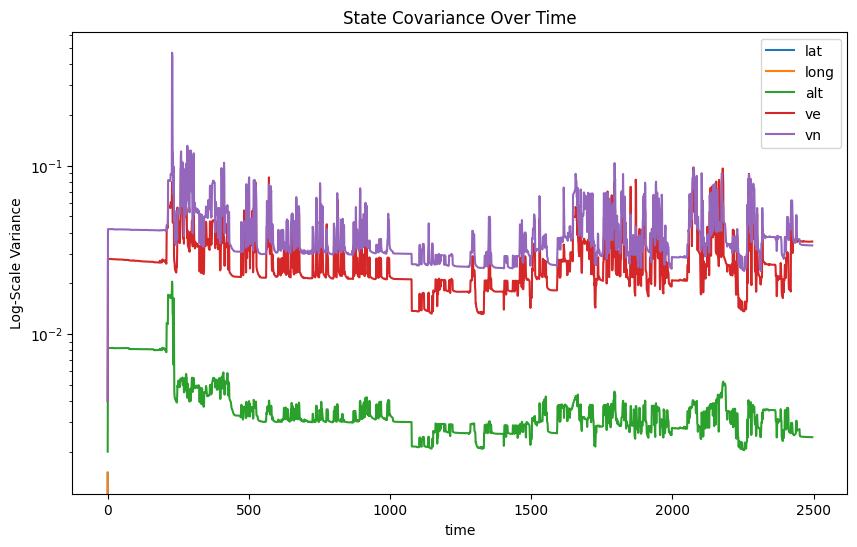

In [24]:
# Create the plot
plt.figure(figsize=(10, 6))

# Plot each of the 8 elements across all epochs
labels = ['lat', 'long', 'alt','ve', 'vn', 'vu', 'Yaw', 'SF', 'bwz']
for i in range(5):
    plt.semilogy(time_grid[0:], cov_diag[i, 0:], label=labels[i])

# Labels and title
plt.xlabel('time')
plt.ylabel('Log-Scale Variance')
plt.title('State Covariance Over Time')

# Legend
plt.legend()
# Save as PDF (optional)
#plt.savefig("state_cov.pdf", format="pdf")

# Show the plot
plt.show()

### Positional Components 

#### Latitude

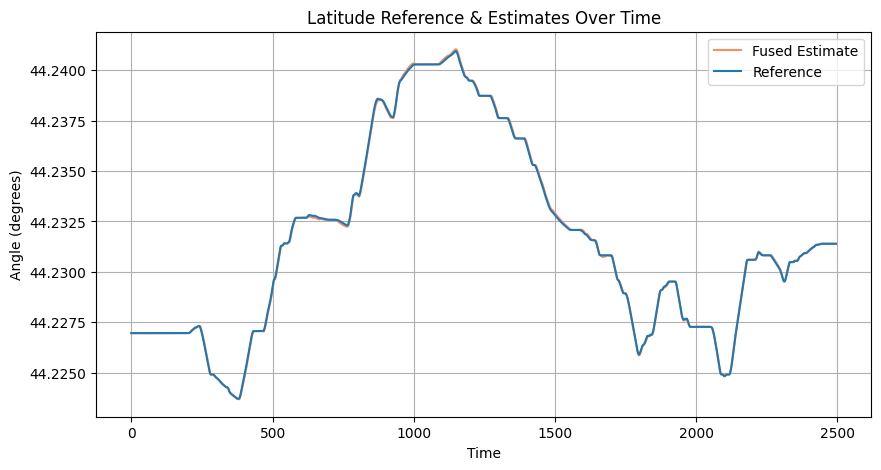

In [25]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, np.degrees(state_estimates[0,:]), label="Fused Estimate", linestyle='-', color='#fc8d62')  # orange
plt.plot(time_grid, np.degrees(ref_data['latitude'][0,:]), label="Reference", linestyle='-', color='#1f77b4')  # Blue

# Labels and title
plt.xlabel("Time")
plt.ylabel("Angle (degrees)")
plt.title("Latitude Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

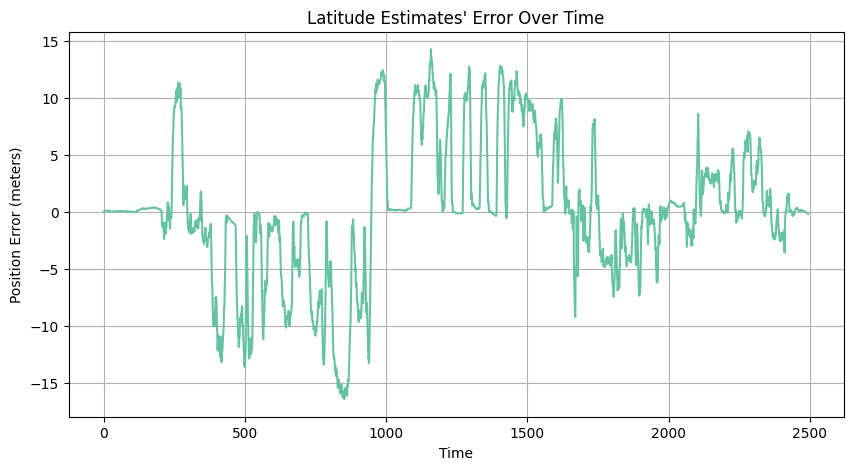

In [26]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, position_errors['north'], linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Position Error (meters)")
plt.title("Latitude Estimates' Error Over Time")

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

#### Longitude

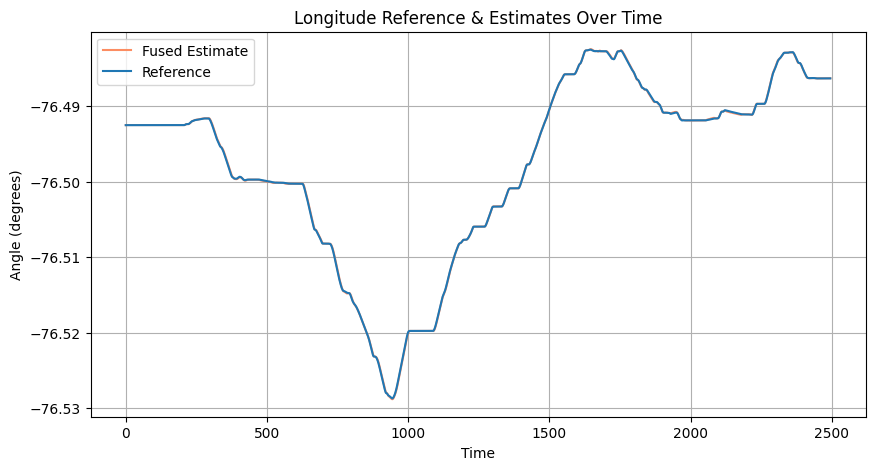

In [27]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, np.degrees(state_estimates[1,:]), label="Fused Estimate", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, np.degrees(ref_data['longitude'][0,:]), label="Reference", linestyle='-', color='#1f77b4')  # Blue

# Labels and title
plt.xlabel("Time")
plt.ylabel("Angle (degrees)")
plt.title("Longitude Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

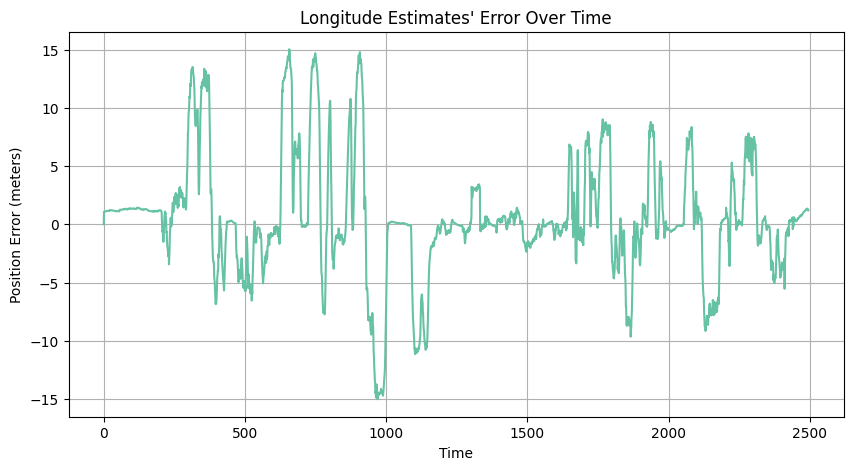

In [28]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, position_errors['east'], linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Position Error (meters)")
plt.title("Longitude Estimates' Error Over Time")

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

#### Lat-Long

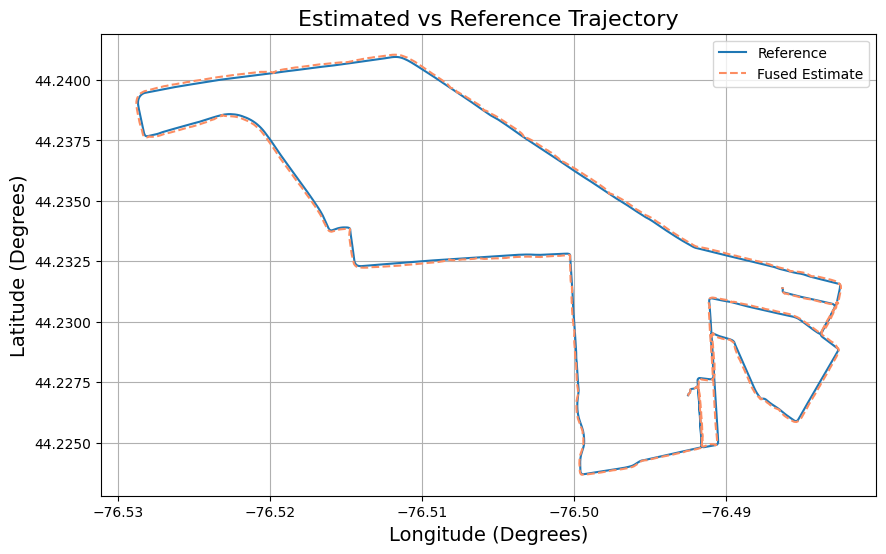

In [44]:
plt.figure(figsize=(10, 6))

# Plot reference trajectory
plt.plot(np.degrees(ref_data['longitude'][0,:]), np.degrees(ref_data['latitude'][0,:]), '-', color='#1f77b4', label="Reference")  # Blue

# Plot high-end estimate trajectory
plt.plot(np.degrees(state_estimates[1,:]), np.degrees(state_estimates[0,:]), '--', color='#fc8d62', label="Fused Estimate")  # Orange

# Labels and title
plt.xlabel("Longitude (Degrees)", fontsize=14)
plt.ylabel("Latitude (Degrees)", fontsize=14)
plt.title("Estimated vs Reference Trajectory", fontsize=16)

# Add a legend
plt.legend()

# Grid for better visualization
plt.grid(True)
#plt.savefig("traj.pdf", format="pdf")
# Show the plot
plt.show()


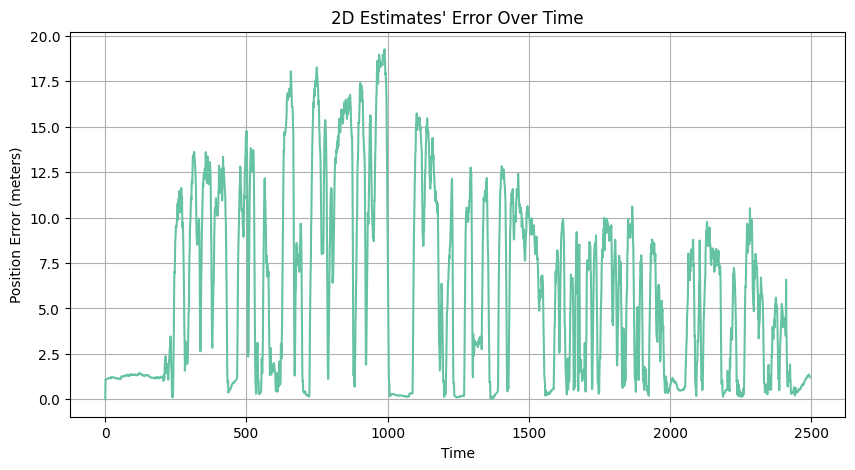

In [30]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, position_errors['2d'], linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Position Error (meters)")
plt.title("2D Estimates' Error Over Time")

# Grid for better visualization
plt.grid(True)
#plt.savefig("out2Derr.pdf", format="pdf")
# Show the plot
plt.show()

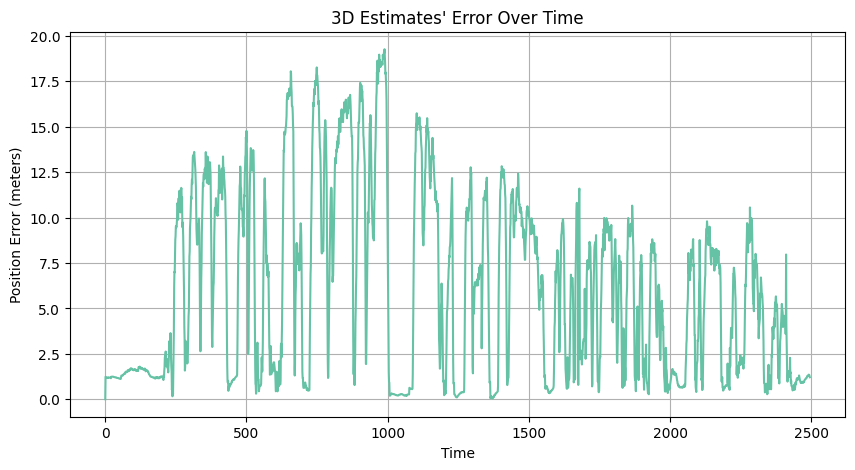

In [31]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, position_errors['3d'], linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Position Error (meters)")
plt.title("3D Estimates' Error Over Time")

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

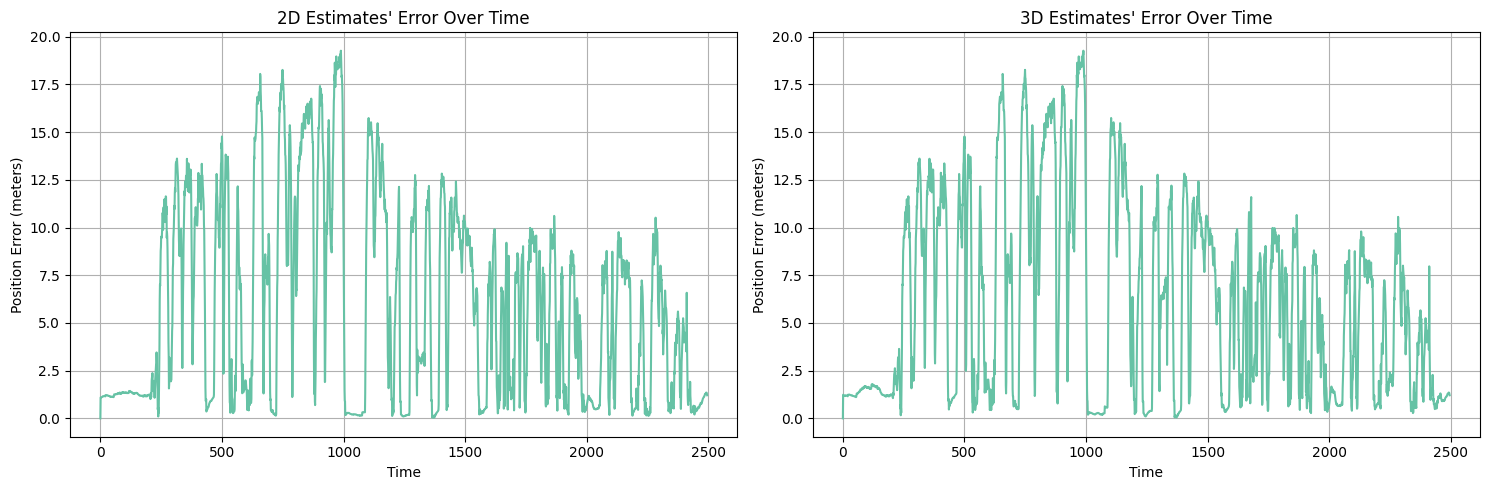

In [32]:
# Create a 1x2 subplot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))  # 1 row, 2 columns

# First plot: 2D position error
axes[0].plot(time_grid, position_errors['2d'], linestyle='-', color='#66c2a5')  # Teal
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Position Error (meters)")
axes[0].set_title("2D Estimates' Error Over Time")
axes[0].grid(True)

# Second plot: 3D position error
axes[1].plot(time_grid, position_errors['3d'], linestyle='-', color='#66c2a5')  # Teal
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Position Error (meters)")
axes[1].set_title("3D Estimates' Error Over Time")
axes[1].grid(True)

# Adjust layout for better spacing
plt.tight_layout()
#plt.savefig("2D3Derr.pdf", format="pdf")
# Show the combined plot
plt.show()


#### Altitude

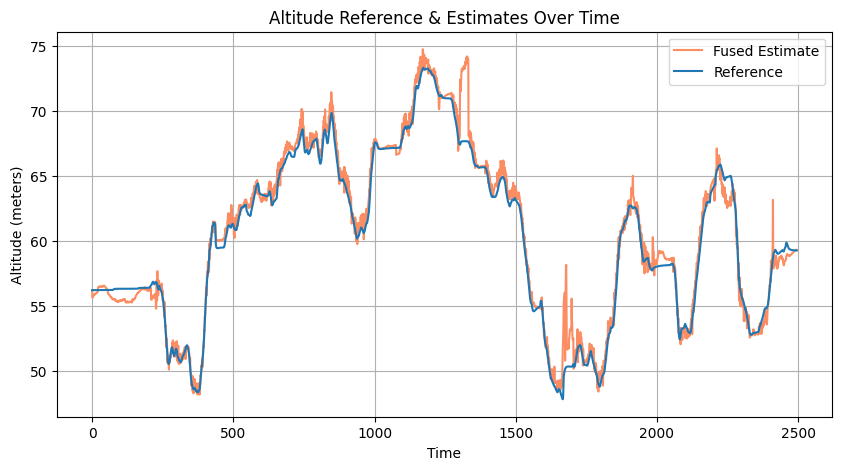

In [33]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, state_estimates[2,:], label="Fused Estimate", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, ref_data['altitude'][0,:], label="Reference", linestyle='-', color='#1f77b4')  # Blue

# Labels and title
plt.xlabel("Time")
plt.ylabel("Altitude (meters)")
plt.title("Altitude Reference & Estimates Over Time")


# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

#plt.savefig("alt_filt.pdf", format="pdf")

# Show the plot
plt.show()

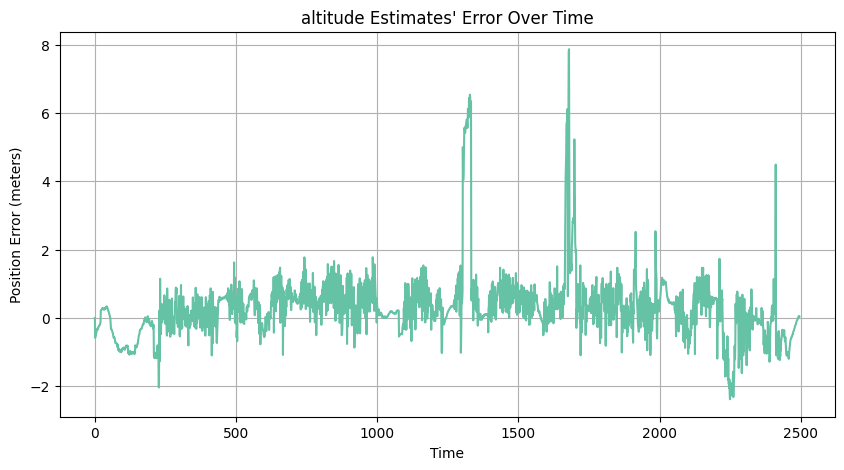

In [34]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, position_errors['altitude'], linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Position Error (meters)")
plt.title("altitude Estimates' Error Over Time")

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

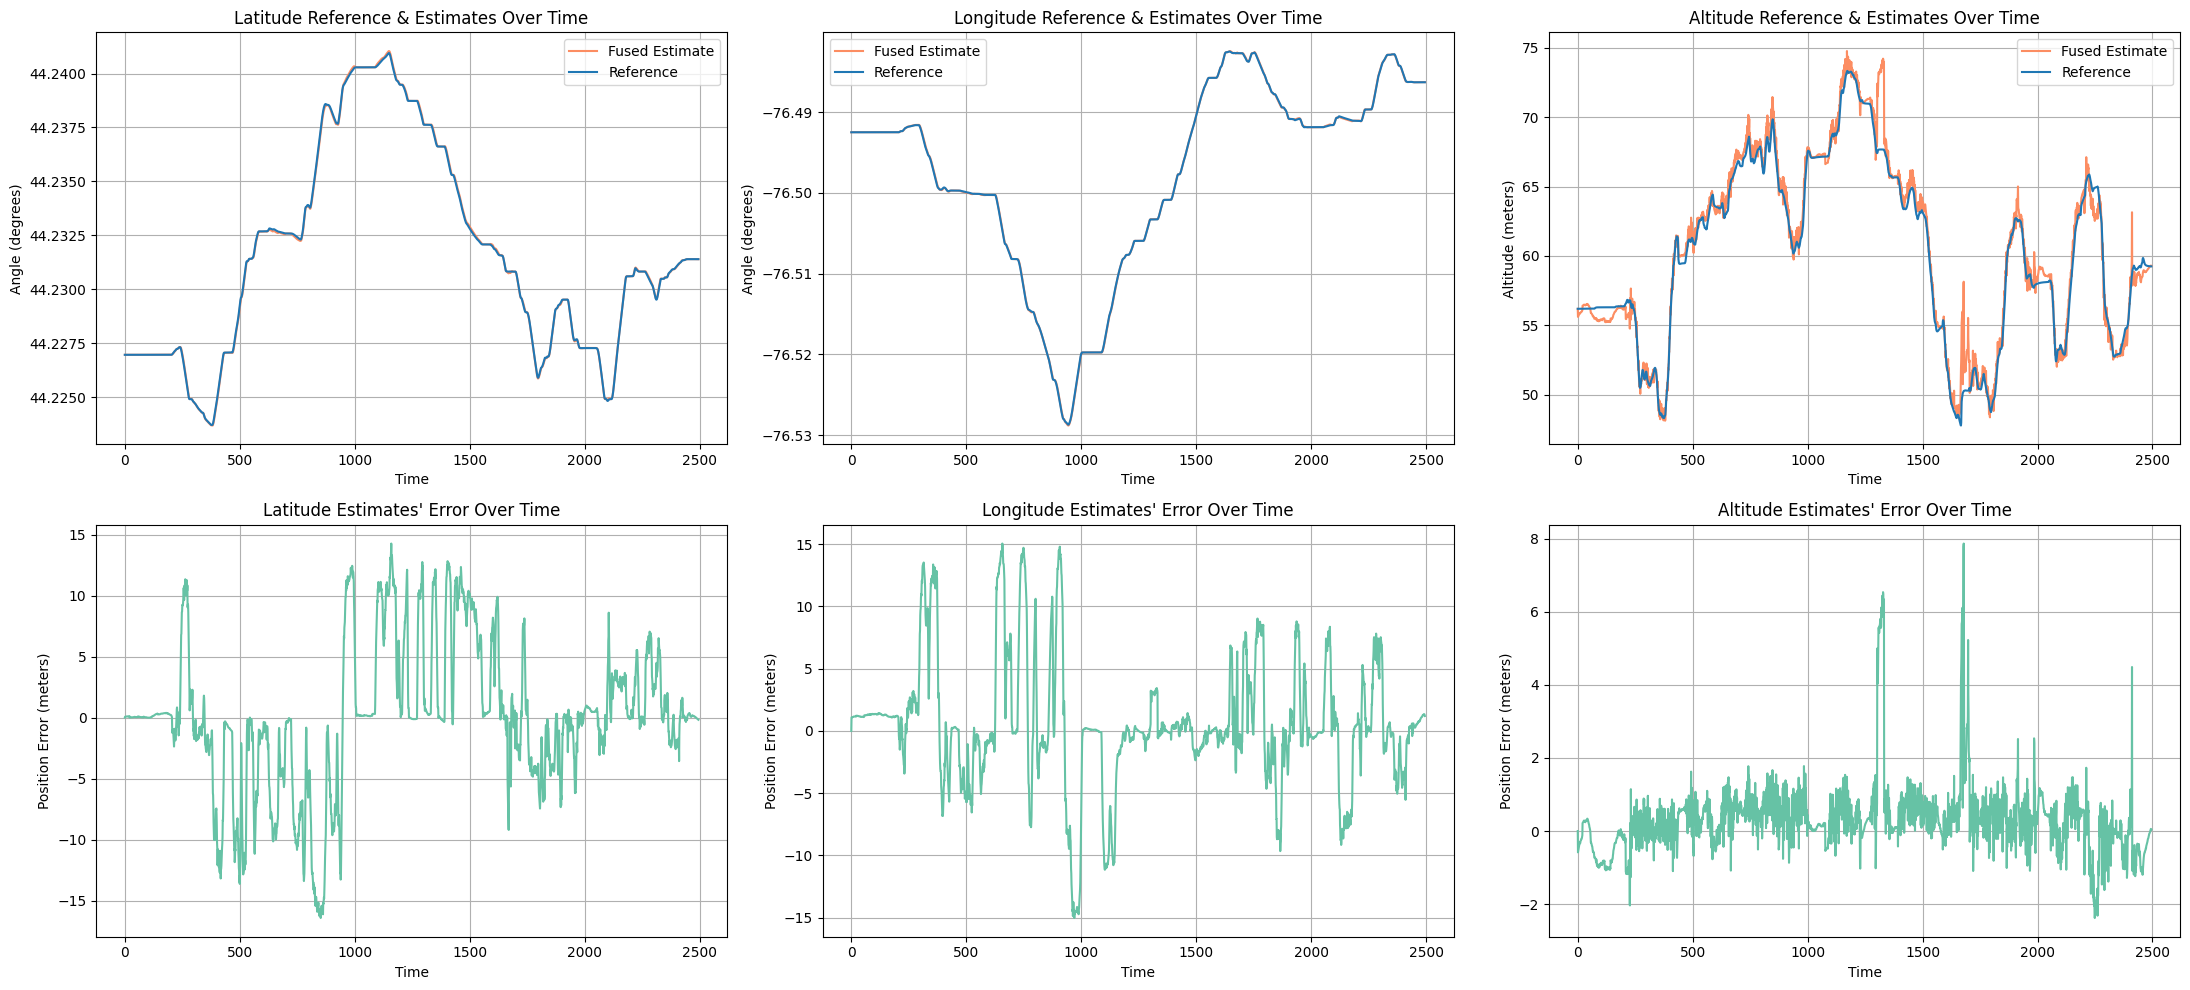

In [35]:
# Create a 2x3 subplot figure
fig, axes = plt.subplots(2, 3, figsize=(22, 10))

# First row: Latitude, Longitude, and Altitude Estimates Over Time
axes[0,0].plot(time_grid, np.degrees(state_estimates[0,:]), label="Fused Estimate", linestyle='-', color='#fc8d62')  # orange
axes[0,0].plot(time_grid, np.degrees(ref_data['latitude'][0,:]), label="Reference", linestyle='-', color='#1f77b4')  # Blue
axes[0, 0].set_xlabel("Time")
axes[0, 0].set_ylabel("Angle (degrees)")
axes[0, 0].set_title("Latitude Reference & Estimates Over Time")
axes[0, 0].legend()
axes[0, 0].grid(True)

axes[0,1].plot(time_grid, np.degrees(state_estimates[1,:]), label="Fused Estimate", linestyle='-', color='#fc8d62')  # Orange
axes[0,1].plot(time_grid, np.degrees(ref_data['longitude'][0,:]), label="Reference", linestyle='-', color='#1f77b4')  # Blue
axes[0, 1].set_xlabel("Time")
axes[0, 1].set_ylabel("Angle (degrees)")
axes[0, 1].set_title("Longitude Reference & Estimates Over Time")
axes[0, 1].legend()
axes[0, 1].grid(True)

axes[0,2].plot(time_grid, state_estimates[2,:], label="Fused Estimate", linestyle='-', color='#fc8d62')  # Orange
axes[0,2].plot(time_grid, ref_data['altitude'][0,:], label="Reference", linestyle='-', color='#1f77b4')  # Blue
axes[0, 2].set_xlabel("Time")
axes[0, 2].set_ylabel("Altitude (meters)")
axes[0, 2].set_title("Altitude Reference & Estimates Over Time")
axes[0, 2].legend()
axes[0, 2].grid(True)

# Second row: Latitude, Longitude, and Altitude Estimates' Error Over Time
axes[1, 0].plot(time_grid, position_errors['north'], linestyle='-', color='#66c2a5')  # Teal
axes[1, 0].set_xlabel("Time")
axes[1, 0].set_ylabel("Position Error (meters)")
axes[1, 0].set_title("Latitude Estimates' Error Over Time")
axes[1, 0].grid(True)

axes[1, 1].plot(time_grid, position_errors['east'], linestyle='-', color='#66c2a5')  # Teal
axes[1, 1].set_xlabel("Time")
axes[1, 1].set_ylabel("Position Error (meters)")
axes[1, 1].set_title("Longitude Estimates' Error Over Time")
axes[1, 1].grid(True)

axes[1, 2].plot(time_grid, position_errors['altitude'], linestyle='-', color='#66c2a5')  # Teal
axes[1, 2].set_xlabel("Time")
axes[1, 2].set_ylabel("Position Error (meters)")
axes[1, 2].set_title("Altitude Estimates' Error Over Time")
axes[1, 2].grid(True)

# Adjust layout to prevent overlapping
plt.tight_layout()

# Save as PDF (optional)
#plt.savefig("out_pos_err.pdf", format="pdf")

# Show the figure
plt.show()

### Velocity Components

#### East Velocity

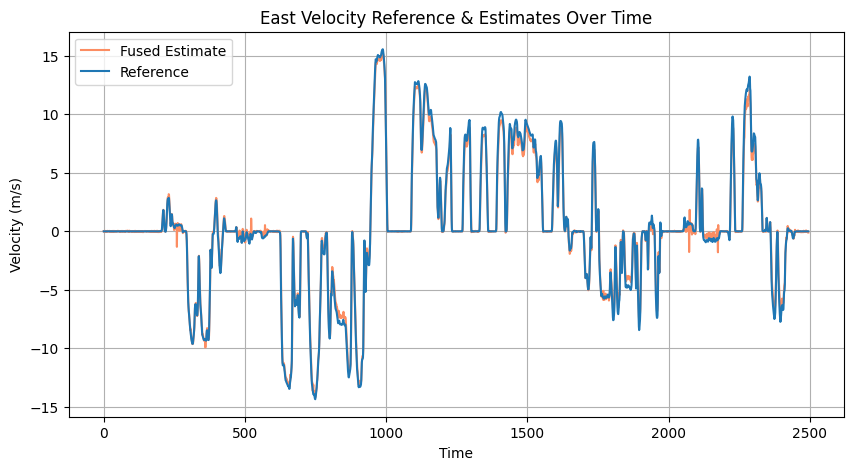

In [36]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, state_estimates[3], label="Fused Estimate", linestyle='-', color='#fc8d62')  # Orange
#plt.plot(time_grid, ins_ests[3,:], label="INS Estimate", linestyle='-', color='#fc8d62')  # Orange
#plt.plot(time_grid, gps_data['velocity_east'][0,:], label="GNSS Estimate", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, ref_data['velocity_east'][0,:], label="Reference", linestyle='-', color='#1f77b4')  # Blue

# Labels and title
plt.xlabel("Time")
plt.ylabel("Velocity (m/s)")
plt.title("East Velocity Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

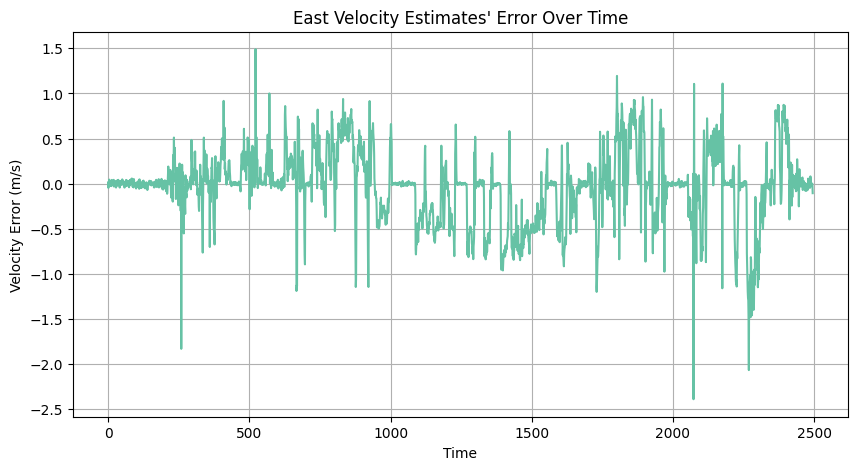

In [37]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, velocity_errors['east'], linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Velocity Error (m/s)")
plt.title("East Velocity Estimates' Error Over Time")

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

#### North Velocity

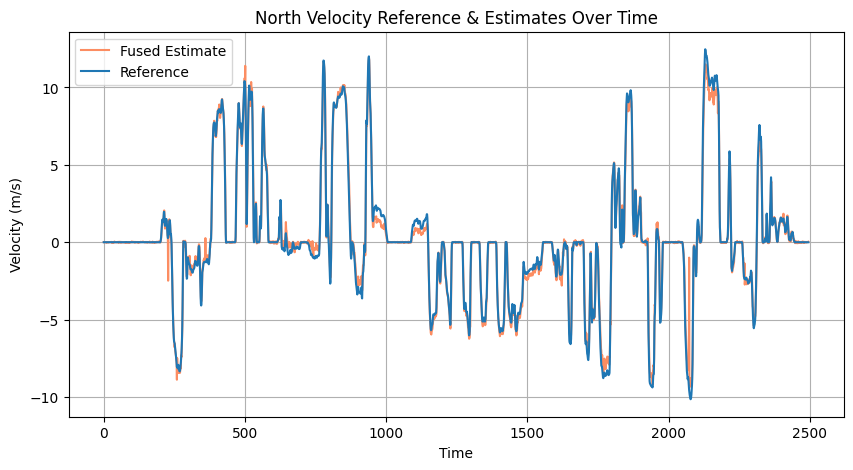

In [38]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, state_estimates[4,:], label="Fused Estimate", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, ref_data['velocity_north'][0,:], label="Reference", linestyle='-', color='#1f77b4')  # Blue

# Labels and title
plt.xlabel("Time")
plt.ylabel("Velocity (m/s)")
plt.title("North Velocity Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

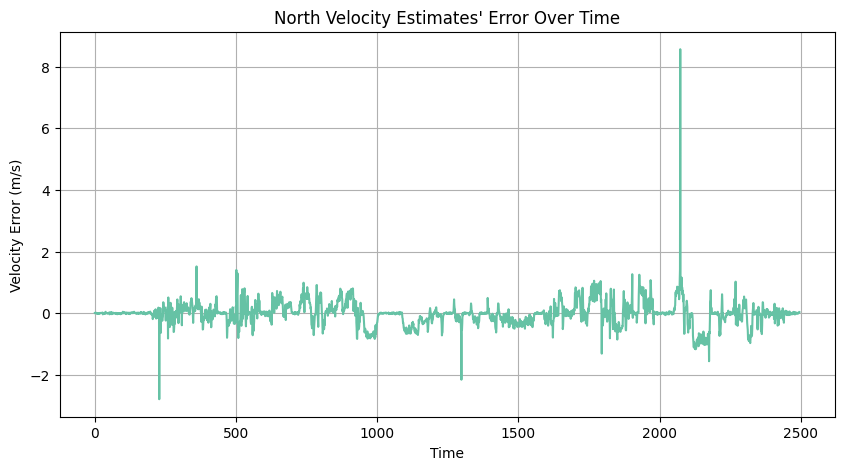

In [39]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, velocity_errors['north'], linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Velocity Error (m/s)")
plt.title("North Velocity Estimates' Error Over Time")

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

#### Up Velocity

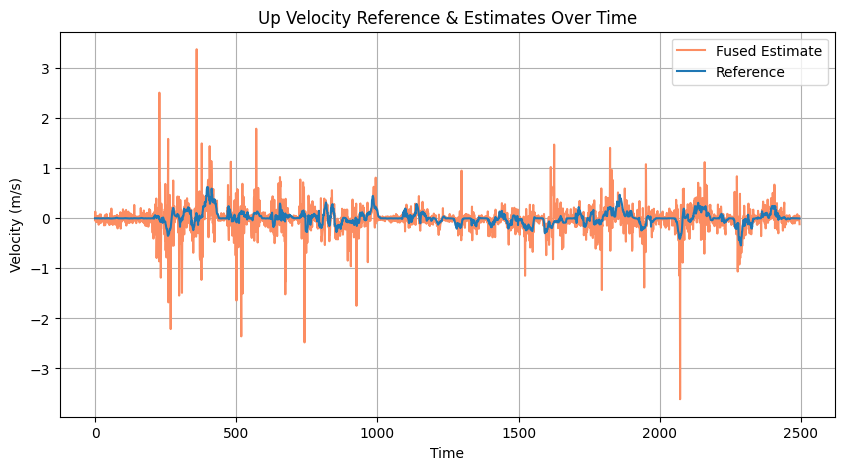

In [40]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, state_estimates[5,:], label="Fused Estimate", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, ref_data['velocity_up'][0,:], label="Reference", linestyle='-', color='#1f77b4')  # Blue

# Labels and title
plt.xlabel("Time")
plt.ylabel("Velocity (m/s)")
plt.title("Up Velocity Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

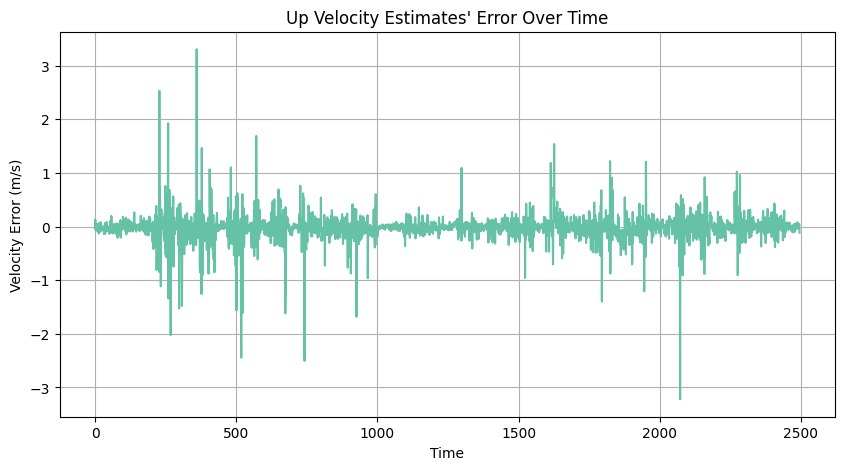

In [41]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, velocity_errors['up'], linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("Velocity Error (m/s)")
plt.title("Up Velocity Estimates' Error Over Time")

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

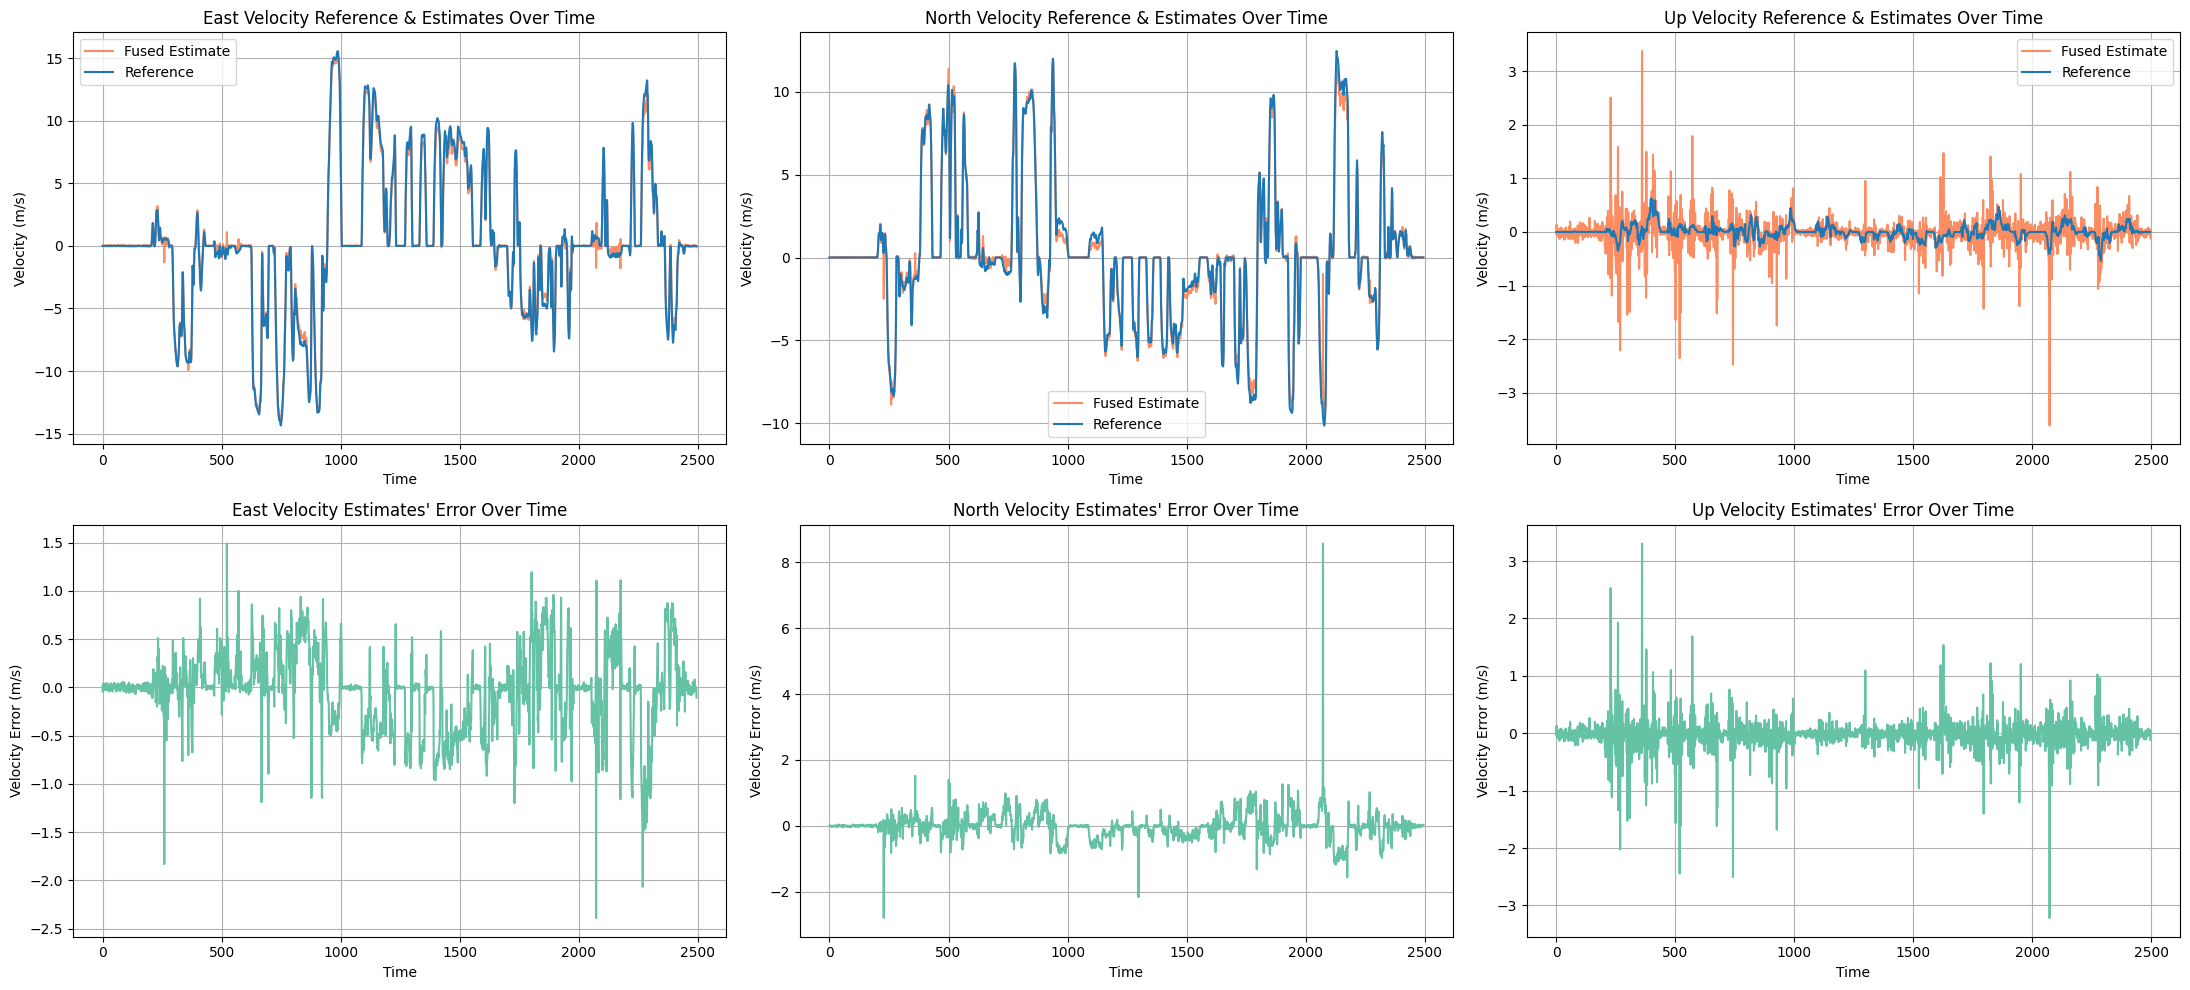

In [42]:
# Create a 2x3 subplot figure
fig, axes = plt.subplots(2, 3, figsize=(22, 10))

# First row: East, North, and Up Velocity Estimates Over Time
axes[0, 0].plot(time_grid, state_estimates[3], label="Fused Estimate", linestyle='-', color='#fc8d62')  # Orange
axes[0, 0].plot(time_grid, ref_data['velocity_east'][0,:], label="Reference", linestyle='-', color='#1f77b4')  # Blue
axes[0, 0].set_xlabel("Time")
axes[0, 0].set_ylabel("Velocity (m/s)")
axes[0, 0].set_title("East Velocity Reference & Estimates Over Time")
axes[0, 0].legend()
axes[0, 0].grid(True)

axes[0, 1].plot(time_grid, state_estimates[4,:], label="Fused Estimate", linestyle='-', color='#fc8d62')  # Orange
axes[0, 1].plot(time_grid, ref_data['velocity_north'][0,:], label="Reference", linestyle='-', color='#1f77b4')  # Blue
axes[0, 1].set_xlabel("Time")
axes[0, 1].set_ylabel("Velocity (m/s)")
axes[0, 1].set_title("North Velocity Reference & Estimates Over Time")
axes[0, 1].legend()
axes[0, 1].grid(True)

axes[0, 2].plot(time_grid, state_estimates[5,:], label="Fused Estimate", linestyle='-', color='#fc8d62')  # Orange
axes[0, 2].plot(time_grid, ref_data['velocity_up'][0,:], label="Reference", linestyle='-', color='#1f77b4')  # Blue
axes[0, 2].set_xlabel("Time")
axes[0, 2].set_ylabel("Velocity (m/s)")
axes[0, 2].set_title("Up Velocity Reference & Estimates Over Time")
axes[0, 2].legend()
axes[0, 2].grid(True)

# Second row: East, North, and Up Velocity Estimates' Error Over Time
axes[1, 0].plot(time_grid, velocity_errors['east'], linestyle='-', color='#66c2a5')  # Teal
axes[1, 0].set_xlabel("Time")
axes[1, 0].set_ylabel("Velocity Error (m/s)")
axes[1, 0].set_title("East Velocity Estimates' Error Over Time")
axes[1, 0].grid(True)

axes[1, 1].plot(time_grid, velocity_errors['north'], linestyle='-', color='#66c2a5')  # Teal
axes[1, 1].set_xlabel("Time")
axes[1, 1].set_ylabel("Velocity Error (m/s)")
axes[1, 1].set_title("North Velocity Estimates' Error Over Time")
axes[1, 1].grid(True)

axes[1, 2].plot(time_grid, velocity_errors['up'], linestyle='-', color='#66c2a5')  # Teal
axes[1, 2].set_xlabel("Time")
axes[1, 2].set_ylabel("Velocity Error (m/s)")
axes[1, 2].set_title("Up Velocity Estimates' Error Over Time")
axes[1, 2].grid(True)

# Adjust layout to prevent overlapping
plt.tight_layout()

# Save as PDF (optional)
#plt.savefig("vel_err.pdf", format="pdf")

# Show the figure
plt.show()

### Azimuth

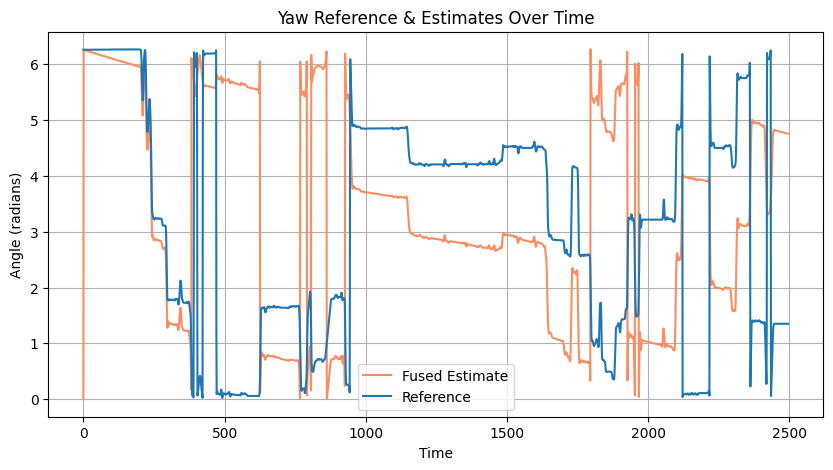

In [43]:
# Plot the data
plt.figure(figsize=(10, 5))

plt.plot(time_grid, ins_ests[6,:], label="Fused Estimate", linestyle='-', color='#fc8d62')  # Orange
plt.plot(time_grid, -1*ref_data['azimuth'][0,:] % (2 * np.pi), label="Reference", linestyle='-', color='#1f77b4')  # Blue

# Labels and title
plt.xlabel("Time")
plt.ylabel("Angle (radians)")
plt.title("Yaw Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()